# Восстановление траектории между наблюдениями
## 07 · Эксперимент со скрытыми точками

**Вопрос:** насколько хорошо простые методы восстанавливают известную позицию самолета, если часть наблюдений скрыта?

Мы используем 10 рейсов публичного пилота OpenSky. Оставляем два конца интервала, скрываем все внутренние точки и сравниваем предсказания с этими точками. Проверяем интервалы **20, 30, 60 и 120 секунд**. Модель ML пока не обучается: сначала устанавливаем ориентиры, которые ей предстоит превзойти.

Проверочный ответ – наблюдение OpenSky. Его собственная погрешность неизвестна. Расхождение около 43 км между источниками остается отдельной нерешенной задачей.

In [1]:
# Подключаем библиотеки для таблиц, расчетов и отображения результатов
from pathlib import Path
import contextlib
import io
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

# Находим корень проекта независимо от папки запуска ноутбука
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'research/c40_geometry/scripts/evaluate_hidden_points.py').exists())
study = root / 'research/c40_geometry'
sys.path.insert(0, str(study / 'scripts'))
# Используем общий код эксперимента и кинематического метода
from evaluate_hidden_points import main as run_experiment, forward
# Включаем вывод графиков внутри ноутбука после импорта расчетных модулей
matplotlib.use('module://matplotlib_inline.backend_inline')
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

# Задаем единое оформление и цвета методов для всех графиков
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
labels = {'nearest': 'Ближайшая точка', 'linear_lat_lon': 'Линейная интерполяция',
          'constant_velocity_sphere': 'Постоянная скорость'}
colors = {'nearest': '#85929E', 'linear_lat_lon': '#00897B',
          'constant_velocity_sphere': '#D65A4A'}
# Загружаем наблюдения и показываем поля, используемые в эксперименте
source = pd.read_csv(study / 'data/public_pilot/EPWA_control_geometry.csv')
display(Markdown(f'**Вход:** {len(source):,} наблюдений, '
                 f'{source.case_flight_id.nunique()} рейсов. Исходный файл сохраняется без изменений.'))
display(source[['case_flight_id', 'time', 'lat', 'lon', 'velocity', 'heading', 'lastposupdate']].head())

**Вход:** 1,243 наблюдений, 10 рейсов. Исходный файл сохраняется без изменений.

,case_flight_id,time,lat,lon,velocity,heading,lastposupdate
0,EXS92K_22219,1571695560,52.319548,-1.480800,195.781598,345.233448,1.571696e+09
1,EXS92K_22219,1571695570,52.335841,-1.487784,195.153367,345.341001,1.571696e+09
2,EXS92K_22219,1571695580,52.353391,-1.495239,194.027927,345.411081,1.571696e+09
3,EXS92K_22219,1571695590,52.370243,-1.502380,193.400841,345.520185,1.571696e+09
4,EXS92K_22219,1571695600,52.386658,-1.509171,192.148794,345.740527,1.571696e+09


### 1. Что означают входные поля

| Поле | Значение в этом эксперименте |
|---|---|
| `case_flight_id` | Идентификатор сопоставленного рейса; единица будущего разбиения |
| `time` | Время снимка, Unix-секунды |
| `lat`, `lon` | Наблюдаемые широта и долгота, градусы |
| `velocity` | Горизонтальная скорость из state vector, м/с |
| `heading` | Направление движения из state vector, градусы |
| `lastposupdate` | Время последнего обновления позиции, Unix-секунды |
| `onground` | Признак нахождения на земле |

Возраст позиции вычисляется как `time − lastposupdate`. Для пилота допускаем возраст **0–2 секунды**, воздушное состояние, корректные координаты и непрерывную исходную сетку 10 секунд. Это выбранные условия эксперимента, не авиационные нормативы. Непригодные строки остаются в исходном файле; через них интервал не строится.

In [2]:
# Пересчитываем эксперимент на исходных наблюдениях
# Подробные результаты сохраняются локально, агрегаты – в reports
# Скрываем длинный технический вывод скрипта и ниже показываем нужные таблицы
with contextlib.redirect_stdout(io.StringIO()):
    run_experiment()
# Читаем аудит входа, ошибки отдельных предсказаний и показатели по рейсам
audit = json.loads((study / 'reports/07_hidden_point_audit.json').read_text(encoding='utf8'))
errors = pd.read_csv(study / 'data/public_pilot/07_hidden_point_errors.csv')
summary = pd.read_csv(study / 'reports/07_hidden_point_summary.csv')
# Сравниваем исходное число наблюдений с числом пригодных для пилота
display(pd.DataFrame(audit['flights']).rename(columns={
    'flight_id': 'Рейс', 'raw_rows': 'Исходных наблюдений', 'eligible_rows': 'Пригодных наблюдений'}))
display(Markdown(f"Получено **{len(errors)//3:,} задач восстановления** и **{len(errors):,} ошибок** трех методов."))

,Рейс,Исходных наблюдений,Пригодных наблюдений
0,ENT73JH_21100,121,109
1,EXS4112_71377,137,126
2,EXS92K_22219,120,107
3,EZY1942_18429,124,113
4,EZY34MD_21230,119,108
5,EZY89BW_37984,132,121
6,RYR4117_60025,123,112
7,RYR67GT_63261,124,113
8,RYR72ZC_66456,130,120
9,RYR9BN_63693,113,101


Получено **18,901 задач восстановления** и **56,703 ошибок** трех методов.

### 2. Что доступно каждому методу

| Метод | Доступные наблюдения | Расчет |
|---|---|---|
| Ближайшая точка | Оба конца | Позиция ближайшего по времени конца; при равенстве – левого |
| Линейная интерполяция | Оба конца | Доля времени внутри интервала определяет долю изменения координат |
| Постоянная скорость | Левый конец | Начальная скорость и направление, движение по сфере радиуса 6371000 м |

Линейный метод получает будущую позицию, а постоянная скорость – только прошлую. Поэтому это сравнение трех практических ориентиров с разной доступной информацией. Скрытые точки не используются для предсказаний. Ошибка каждого метода измеряется расстоянием WGS84 по формуле Vincenty.

Ниже показан один воспроизводимо выбранный интервал 120 секунд. Выбираем **первое пригодное окно по времени** основного рейса, не окно с самой удачной ошибкой.

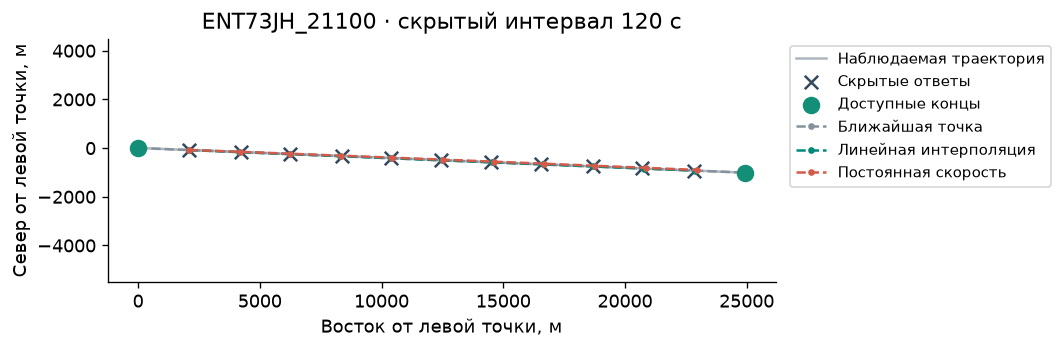

In [3]:
# Выбираем первое пригодное окно основного рейса без отбора по величине ошибки
flight = 'ENT73JH_21100'
left_time = errors.query('flight_id == @flight and gap_s == 120').left_time.min()
track = source[source.case_flight_id.eq(flight)].sort_values('time')
window = track[track.time.between(left_time, left_time+120)].copy()
# Оставляем концы доступными, внутренние наблюдения используем как ответы
a, b = window.iloc[0], window.iloc[-1]
hidden = window.iloc[1:-1]
# Доля прошедшего времени определяет положение между концами интервала
dt = hidden.time.to_numpy()-a.time
w = dt/120
# Линейно восстанавливаем координаты по двум доступным концам
linear = np.column_stack([a.lat+w*(b.lat-a.lat), a.lon+w*(b.lon-a.lon)])
# Продолжаем движение с направлением и скоростью левого конца
kinematic = np.array([forward(a.lat, a.lon, a.heading, a.velocity*t) for t in dt])
# При равной удаленности во времени выбираем левую точку
nearest = np.array([(a.lat, a.lon) if t <= 60 else (b.lat, b.lon) for t in dt])

# Локальная проекция нужна только для рисунка, ошибки считаются на WGS84
def local(points):
    return ((points[:, 1]-a.lon)*111320*np.cos(np.radians(a.lat)),
            (points[:, 0]-a.lat)*111200)
# Показываем скрытые ответы, доступные концы и предсказания на одном рисунке
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(*local(window[['lat','lon']].to_numpy()), color='#34495E', alpha=.4, label='Наблюдаемая траектория')
ax.scatter(*local(hidden[['lat','lon']].to_numpy()), marker='x', s=65, color='#34495E', label='Скрытые ответы')
ax.scatter(*local(np.array([[a.lat,a.lon],[b.lat,b.lon]])), s=90, color='#148F77', label='Доступные концы', zorder=5)
for method, points in [('nearest', nearest), ('linear_lat_lon', linear), ('constant_velocity_sphere', kinematic)]:
    ax.plot(*local(points), '.--', color=colors[method], label=labels[method])
ax.set(xlabel='Восток от левой точки, м', ylabel='Север от левой точки, м',
       title=f'{flight} · скрытый интервал 120 с', aspect='equal')
east, north = local(window[['lat','lon']].to_numpy())
# Добавляем поля вокруг траектории и выносим легенду за область данных
margin = max(np.ptp(east), np.ptp(north))*.18
ax.set_ylim(north.min()-margin, north.max()+margin)
ax.legend(fontsize=9, loc='upper left', bbox_to_anchor=(1.01,1))
plt.tight_layout()
plt.show()

### 3. Как растет ошибка при увеличении пропуска

В таблице ниже средняя ошибка сначала считается **внутри каждого рейса**, затем усредняется между рейсами. Так длинный рейс не получает больший вес только из-за числа точек. На графиках тонкие линии – отдельные рейсы, толстые – среднее соответствующего показателя по 10 рейсам.

Окна перекрываются, а одна точка может быть ответом в нескольких окнах. Поэтому это описательные показатели; число строк не является числом независимых испытаний. Среднее рейсовых медиан и среднее рейсовых P95 не являются общей медианой и общим P95.

method,Постоянная скорость,Линейная интерполяция,Ближайшая точка
"Интервал между концами, с",,,
20,51.1,42.7,1422.5
30,83.3,60.8,1417.6
60,266.5,154.4,2565.4
120,981.0,504.0,4675.8


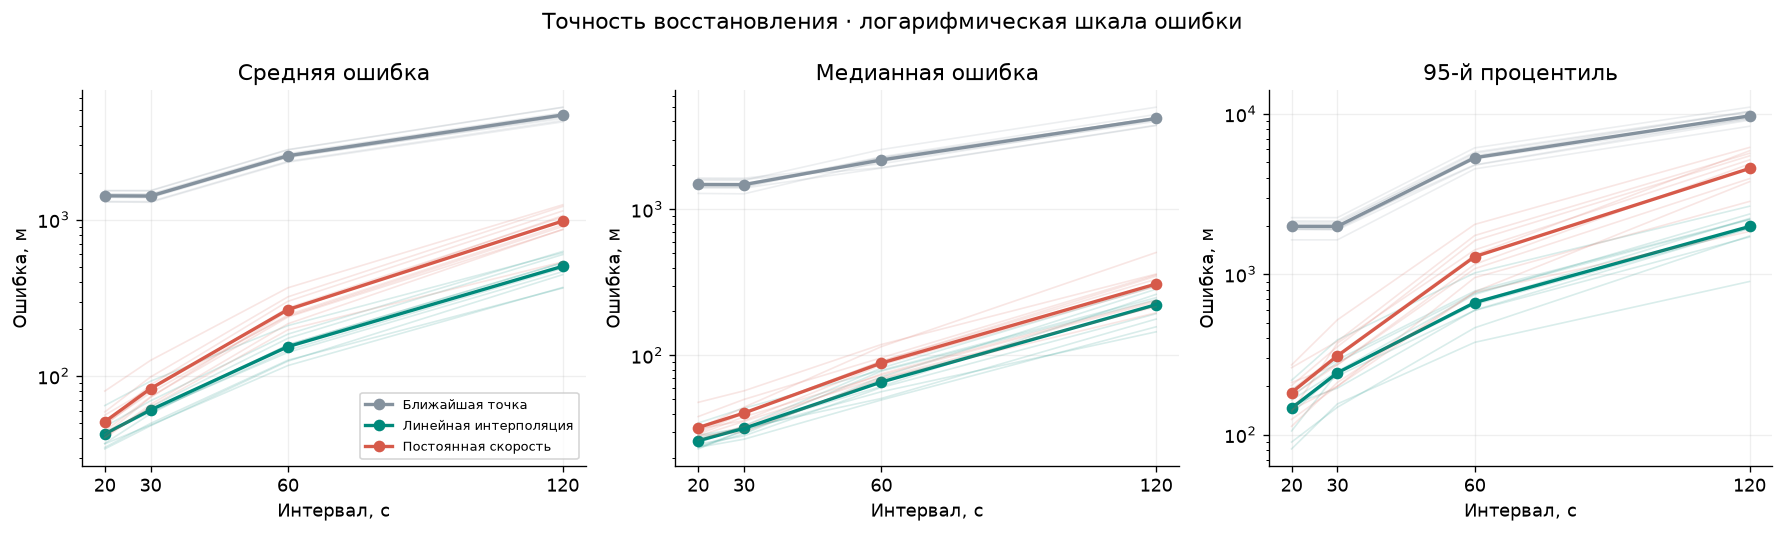

In [4]:
# Усредняем рейсовые показатели с одинаковым весом каждого рейса
macro = summary.groupby(['gap_s', 'method'])[['mean_m','median_m','p95_m']].mean().reset_index()
# Разворачиваем средние ошибки в таблицу для сравнения методов
table = macro.pivot(index='gap_s', columns='method', values='mean_m').rename(columns=labels)
table.index.name = 'Интервал между концами, с'
display(table.round(1))
# Отдельно показываем среднее, медиану и хвост распределения ошибок
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric, title in zip(axes, ['mean_m','median_m','p95_m'],
                            ['Средняя ошибка', 'Медианная ошибка', '95-й процентиль']):
    for method in labels:
        # Тонкие линии показывают различия между отдельными рейсами
        for _, group in summary[summary.method.eq(method)].groupby('flight_id'):
            ax.plot(group.gap_s, group[metric], color=colors[method], alpha=.15, linewidth=1)
        # Толстая линия показывает среднее рейсовых показателей
        group = macro[macro.method.eq(method)]
        ax.plot(group.gap_s, group[metric], 'o-', color=colors[method], label=labels[method], linewidth=2)
    # Логарифмическая шкала позволяет сравнить ошибки от десятков метров до километров
    ax.set(title=title, xlabel='Интервал, с', ylabel='Ошибка, м', yscale='log', xticks=[20,30,60,120])
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.suptitle('Точность восстановления · логарифмическая шкала ошибки')
plt.tight_layout()
plt.show()

### 4. Изменение направления и сложность восстановления

Для интервала 120 секунд группируем окна по абсолютному изменению направления между концами. Границы 5° и 15° – исследовательские категории. По концам нельзя увидеть все повороты внутри окна: самолет мог изменить направление и вернуться к исходному. Показатель используется только для описания сложности, не как доказательство причин ошибки.

method,Постоянная скорость,Линейная интерполяция,Ближайшая точка
turn_group,,,
До 5°,326.2,159.1,5058.4
5–15°,827.8,280.5,4545.6
Более 15°,2236.0,1179.9,3765.1


turn_group
До 5°        529
5–15°        111
Более 15°    309
Name: Число окон, dtype: int64

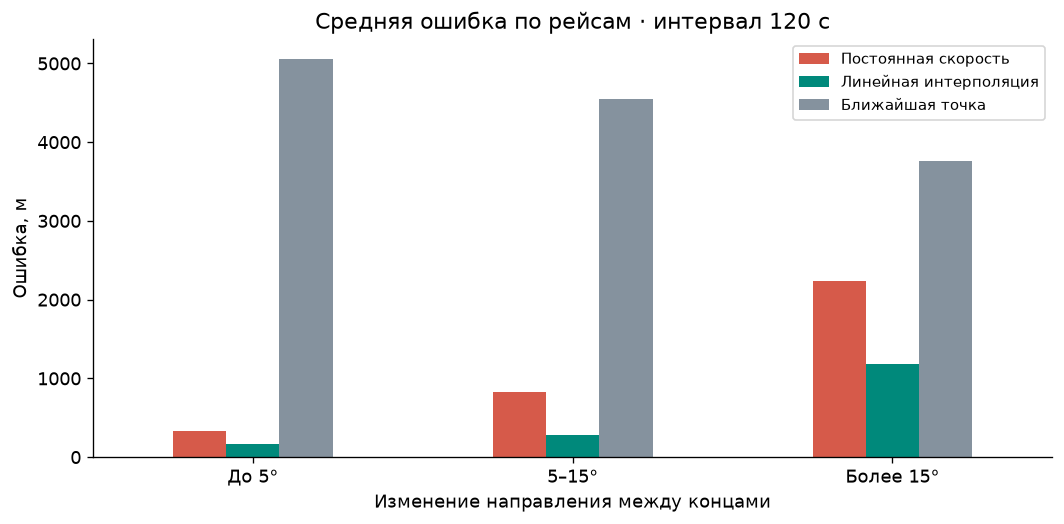

In [5]:
# Фиксируем длину интервала, чтобы не смешивать влияние пропуска и направления
turns = errors[errors.gap_s.eq(120)].copy()
# Группируем по изменению направления между концами, а не по всему пути внутри окна
turns['turn_group'] = pd.cut(turns.endpoint_heading_change_deg, [-.001,5,15,180],
                            labels=['До 5°', '5–15°', 'Более 15°'])
# Сначала считаем ошибки внутри рейса, затем усредняем между рейсами
per_flight = turns.groupby(['flight_id','turn_group','method'], observed=True).error_m.mean().reset_index()
turn_table = per_flight.groupby(['turn_group','method'], observed=True).error_m.mean().unstack().rename(columns=labels)
display(turn_table.round(1))
# Считаем уникальные окна, исключая повторы по скрытым точкам и методам
display(turns[['flight_id','left_time','turn_group']].drop_duplicates().groupby('turn_group', observed=True).size().rename('Число окон'))
ax = turn_table.plot.bar(color=[colors[m] for m in turn_table.rename(columns={v:k for k,v in labels.items()}).columns], figsize=(9,4.5))
ax.set(title='Средняя ошибка по рейсам · интервал 120 с', xlabel='Изменение направления между концами', ylabel='Ошибка, м')
ax.tick_params(axis='x', rotation=0)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 5. Что получили и что проверять дальше

Следующая ячейка формулирует вывод из текущих расчетов. Преимущество простого метода еще не говорит о том, сможет ли ML улучшить его.

In [6]:
# Сравниваем средние ошибки методов в каждом сочетании рейса и интервала
means = summary.pivot(index=['flight_id','gap_s'], columns='method', values='mean_m')
wins = int((means.linear_lat_lon < means.constant_velocity_sphere).sum())
display(Markdown(f'Линейная интерполяция имеет меньшую среднюю ошибку, чем постоянная скорость, '
                 f'в **{wins} из {len(means)}** сочетаний рейса и интервала.'))
# Показываем подробные показатели линейного метода для основного рейса
ent = summary.query('flight_id == @flight and method == "linear_lat_lon"')
display(ent[['gap_s','targets','mean_m','median_m','p95_m','max_m']].round(1))
# Проверяем сопоставимость методов: одна и та же цель должна иметь три результата
key = ['flight_id','gap_s','left_time','target_time']
assert errors.groupby(key).method.nunique().eq(3).all()
# Проверяем корректность ошибок и полноту сочетаний рейсов, интервалов и методов
assert np.isfinite(errors.error_m).all() and errors.error_m.ge(0).all()
assert len(summary) == source.case_flight_id.nunique()*4*3
display(Markdown('**Проверки завершены:** для каждой цели есть три метода; ошибки конечны и неотрицательны.'))

Линейная интерполяция имеет меньшую среднюю ошибку, чем постоянная скорость, в **40 из 40** сочетаний рейса и интервала.

,gap_s,targets,mean_m,median_m,p95_m,max_m
1,20,105,35.0,23.5,105.7,209.7
4,30,206,49.8,26.7,243.0,410.9
7,60,485,126.5,49.6,647.7,1245.5
10,120,935,365.7,157.1,1920.2,3693.4


**Проверки завершены:** для каждой цели есть три метода; ошибки конечны и неотрицательны.

### Ограничения и переход к ML

Все рейсы относятся к одному пилоту; переносимость на другие даты и аэропорты не проверена. Порог свежести позиции выбран для первого расчета: нужно проверить чувствительность к нему. В будущем добавим кинематический метод с обоими концами, чтобы сравнение доступной информации было симметричным.

Для ML все окна одного рейса попадут в одну часть: train, validation или test. Преобразования и параметры обучаются на train, выбор модели выполняется на validation. Этот пилот уже просмотрен и используется для разработки; для итогового вывода нужен отдельный набор рейсов. Доверительные интервалы следует строить с учетом группировки по полетам.

**Следующий вопрос:** может ли модель предсказывать поправку к линейной интерполяции и уменьшать ошибку на новых рейсах, особенно при больших пропусках и поворотах?

Скрипт расчета: `scripts/evaluate_hidden_points.py`. Протокол: `notes/07_hidden_points_protocol.md`. Происхождение наблюдений и контрольные суммы архивов описаны в предыдущих этапах 05–06. Подробные ошибки и исходные данные хранятся локально; ноутбук сохраняет агрегаты и наглядный пример.